In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import scipy.optimize as opt

In [2]:
path=r'C:\Users\Afaq_Lite\Downloads\ex2data2.txt'
data=pd.read_csv(path,names=['Test 1','Test 2','Accepted'])
print(data)

       Test 1    Test 2  Accepted
0    0.051267  0.699560         1
1   -0.092742  0.684940         1
2   -0.213710  0.692250         1
3   -0.375000  0.502190         1
4   -0.513250  0.465640         1
..        ...       ...       ...
113 -0.720620  0.538740         0
114 -0.593890  0.494880         0
115 -0.484450  0.999270         0
116 -0.006336  0.999270         0
117  0.632650 -0.030612         0

[118 rows x 3 columns]


In [3]:
data.head(10)

,Test 1,Test 2,Accepted
0,0.051267,0.699560,1
1,-0.092742,0.684940,1
2,-0.213710,0.692250,1
3,-0.375000,0.502190,1
4,-0.513250,0.465640,1
5,-0.524770,0.209800,1
6,-0.398040,0.034357,1
7,-0.305880,-0.192250,1
8,0.016705,-0.404240,1
9,0.131910,-0.513890,1


In [4]:
data.describe()

,Test 1,Test 2,Accepted
count,118.000000,118.000000,118.000000
mean,0.054779,0.183102,0.491525
std,0.496654,0.519743,0.502060
min,-0.830070,-0.769740,0.000000
25%,-0.372120,-0.254385,0.000000
50%,-0.006336,0.213455,0.000000
75%,0.478970,0.646563,1.000000
max,1.070900,1.108900,1.000000


In [5]:
positive=data[data['Accepted'].isin([1])]
negative=data[data['Accepted'].isin([0])]
print(positive.count(),'\n****')
print(negative.count())

Test 1      58
Test 2      58
Accepted    58
dtype: int64 
****
Test 1      60
Test 2      60
Accepted    60
dtype: int64


Text(0, 0.5, 'Test 2 Score')

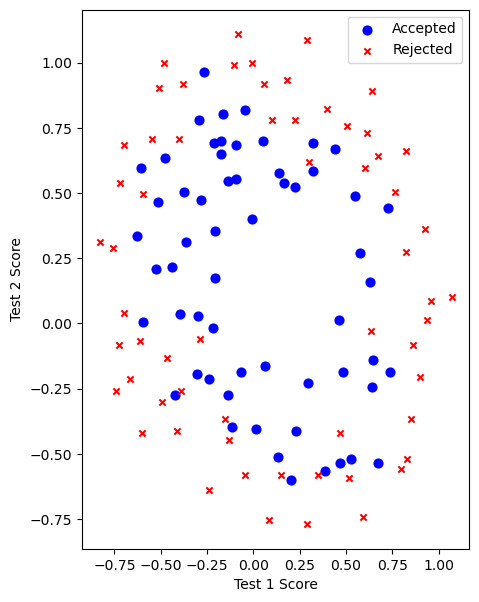

In [6]:
#رسم البوزتيف و النيجتف بأمر سكاتر
fig,ax=plt.subplots(figsize=(5,7))
ax.scatter(positive["Test 1"],positive["Test 2"],s=40,
           c='b', marker='o',label='Accepted')
ax.scatter(negative["Test 1"],negative["Test 2"],s=20,
           c='r', marker='x',label='Rejected')
ax.legend()
ax.set_xlabel('Test 1 Score')
ax.set_ylabel('Test 2 Score')


In [ ]:
dgree=6
x1=data['Test 1']
x2=data['Test 2']
print(x1,'\n*****',x2)

0      0.051267
1     -0.092742
2     -0.213710
3     -0.375000
4     -0.513250
         ...   
113   -0.720620
114   -0.593890
115   -0.484450
116   -0.006336
117    0.632650
Name: Test 1, Length: 118, dtype: float64 
***** 0      0.699560
1      0.684940
2      0.692250
3      0.502190
4      0.465640
         ...   
113    0.538740
114    0.494880
115    0.999270
116    0.999270
117   -0.030612
Name: Test 2, Length: 118, dtype: float64


In [ ]:
X_mapped = pd.DataFrame()
X_mapped['Ones'] = np.ones(len(data))

,Test 1,Test 2,Accepted,Ones
0,0.051267,0.699560,1,1
1,-0.092742,0.684940,1,1
2,-0.213710,0.692250,1,1
3,-0.375000,0.502190,1,1
4,-0.513250,0.465640,1,1
5,-0.524770,0.209800,1,1
6,-0.398040,0.034357,1,1


In [ ]:
for i in range(1,dgree+1):
    #print(i)
    for j in range(0,i+1):
       # print('j=',j)
        data['f'+str(i)+str(j)]= np.power(x1,i-j)*np.power(x2,j)
    #print(data.head(3))    

In [ ]:
# هنعمل حذف لتست ون وتست تو عشان مش محتاجينهم
X = np.array(X_mapped.values)
y = np.array(data.iloc[:, 2:3].values) # عمود Accepted الأصلي
theta = np.zeros(X.shape[1])

In [11]:
print (data.head(3))

   Accepted  Ones       f10       f20       f21       f30       f31       f32  \
0         1     1  0.051267  0.002628  0.035864  0.000135  0.001839  0.025089   
1         1     1 -0.092742  0.008601 -0.063523 -0.000798  0.005891 -0.043509   
2         1     1 -0.213710  0.045672 -0.147941 -0.009761  0.031616 -0.102412   

        f40       f41       f42       f43  
0  0.000007  0.000094  0.001286  0.017551  
1  0.000074 -0.000546  0.004035 -0.029801  
2  0.002086 -0.006757  0.021886 -0.070895  


In [12]:
#عمل دالة السيجمويد
def sigmoid(z):
    return 1/(1+np.exp(-z))
    

In [ ]:
# cost function
def costReg(theta,x ,y,lr):
    theta=np.matrix(theta)
    x=np.matrix(x)
    y=np.matrix(y)
    first_part=np.multiply(-y,np.log(sigmoid(x*theta.T)))
    second_part=np.multiply((1-y),np.log(1-sigmoid(x*theta.T)))
    reg=(lr/(2*len(x))*np.sum(np.power(theta[:,1:theta.shape[1]],2)))
    return np.sum(first_part-second_part)/ (len(x))+reg

In [14]:
def gradientReg(theta,x,y,learningRate):
    theta=np.matrix(theta)
    x=np.matrix(x)
    y=np.matrix(y)
    parameters=int(theta.ravel().shape[1])
    grad=np.zeros(parameters)
    error= sigmoid(x*theta.T)-y
    for i in range(parameters):
        term=np.multiply(error,x[:,i])
        if (i==0):
            grad[i]=np.sum(term)/len(x)
        else:
            grad[i]=np.sum(term)/len(x)+((learningRate/len(x))*theta[0,i])
    return grad
    

In [15]:
cols=data.shape[1]
print(cols)

12


In [16]:
x2=data.iloc[:,1:cols]
x2.head()

,Ones,f10,f20,f21,f30,f31,f32,f40,f41,f42,f43
0,1,0.051267,0.002628,0.035864,0.000135,0.001839,0.025089,0.000007,0.000094,0.001286,0.017551
1,1,-0.092742,0.008601,-0.063523,-0.000798,0.005891,-0.043509,0.000074,-0.000546,0.004035,-0.029801
2,1,-0.213710,0.045672,-0.147941,-0.009761,0.031616,-0.102412,0.002086,-0.006757,0.021886,-0.070895
3,1,-0.375000,0.140625,-0.188321,-0.052734,0.070620,-0.094573,0.019775,-0.026483,0.035465,-0.047494
4,1,-0.513250,0.263426,-0.238990,-0.135203,0.122661,-0.111283,0.069393,-0.062956,0.057116,-0.051818


In [17]:
y2=data.iloc[:,0:1]#=Accepted
print(y2)

     Accepted
0           1
1           1
2           1
3           1
4           1
..        ...
113         0
114         0
115         0
116         0
117         0

[118 rows x 1 columns]


In [18]:
x2=np.array(x2.values)
y2=np.array(y2.values)
theta2=np.zeros(x2.shape[1])
print(theta2)

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [19]:
learningRate=.09 #= alpha

In [20]:
rcost=costReg(theta2,x2,y2,learningRate)
print(rcost)

0.6931471805599454


In [21]:
result=opt.fmin_tnc(func=costReg,x0=theta2,fprime=gradientReg,args=(x2,y2,learningRate))

print(result)

(array([ 0.00142144,  0.00109446, -0.00433805, -0.0025296 ,  0.00125731,
       -0.00051848, -0.00208592, -0.0032354 ,  0.00012138, -0.0034851 ,
       -0.00025906]), 94, 4)


In [22]:
def predict(theta, x):
    # حساب الاحتمالات
    probability = sigmoid(x * theta.T)
    # التعديل: تحويل الاحتمالات الأكبر من أو تساوي 0.5 إلى 1، والباقي إلى 0
    # باستخدام .astype(int) نحصل على مصفوفة من 0 و 1 مباشرة دون حلقات تكرارية
    return (probability >= 0.5).astype(int)

# 1. حساب مصفوفة التنبؤات (ستكون مصفوفة عمودية ثنائية الأبعاد)
theta_min = np.matrix(result[0])
predictions = predict(theta_min, x2)

# 2. مقارنة المصفوفات مباشرة (دون الحاجة لـ zip أو حلقات تكرارية)
# نقارن المصفوفة predictions بالمصفوفة y مباشرة لمعرفة المتطابق
correct = (predictions == y2).astype(int)

# 3. حساب نسبة الدقة من خلال إيجاد المتوسط وضربة في 100
# استخدام np.mean يحسب النسبة مباشرة وبدقة عالية
accuracy = np.mean(correct) * 100

print(f"Accuracy: {accuracy:.2f}%")

Accuracy: 68.64%
